# Assignment 5: Four models of a bioreactor
**Released:** L15 (2026-10-21) · **Due:** Wednesday 2026-10-28 · **6 points on Canvas.**

## Exporting and submitting your homework

0. Work in Google Colab. Open this notebook from [this link](https://colab.research.google.com/github/jkitchin/f26-06763/blob/main/course/assignments/a05.ipynb) (or "Open in Colab" on the course page), then File > Save a copy in Drive, and work in your copy.

1. Run every cell from top to bottom (Runtime > Run all), so that all outputs and plots are in the notebook.

2. Export the notebook as a PDF: File > Print, then choose "Save as PDF" as the destination.

3. Check the PDF before you submit it. It is your responsibility to make sure the PDF exported correctly: every code cell, output, plot and answer must be in it and readable. Equations from the problem statement need not render perfectly, as long as your answers are clear.

4. Submit the PDF to Canvas.

Consider a continuous bioreactor in which the biomass (cells) grows by consuming substrate. Five experiments were run on it, each from a different initial condition. Build four models, use each one to predict experiment 5, and compare the predictions.

The four models are of two kinds, each without and with physics:

| | Data only | Data and physics |
|---|---|---|
| **A model of one trajectory**: time $\mapsto (X, S)$ | Problem 1: neural network of time ([Lecture 13](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/notes.html), [`l13-pinn-jax.ipynb`](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/l13-pinn-jax.html)) | Problem 2: physics-informed neural network, PINN ([Lecture 13](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/notes.html), [`l13-pinn-jax.ipynb`](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/l13-pinn-jax.html)) |
| **A model of the reactor**: state $\mapsto$ its next value or its rate of change | Problem 3: neural-network time-series model ([Lecture 8](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l08/notes.html), [Lecture 9](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l09/notes.html)) | Problem 4: neural ODE, ordinary differential equation ([Lecture 13](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/notes.html), [`l13-neural-dae.ipynb`](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/l13-neural-dae.html)) |

- A model of one trajectory takes the time as its input, so it describes one experiment, and it can learn only from that experiment. Problems 1 and 2 train on the first 40 s of experiment 5 and predict the rest.
- A model of the reactor takes the state as its input. Its rule, from the state now to how the state changes, is the same in every experiment, because every experiment runs the same reactor. So Problems 3 and 4 learn from experiments 1 to 4 and predict experiment 5 from its initial condition.
- Problem 5 compares the four.

Only the top row isolates the effect of the physics: Problems 1 and 2 differ only in the physics term. Problems 3 and 4 also differ in how they model time (discrete steps against a continuous ODE) and in what they fit (one step against whole trajectories).

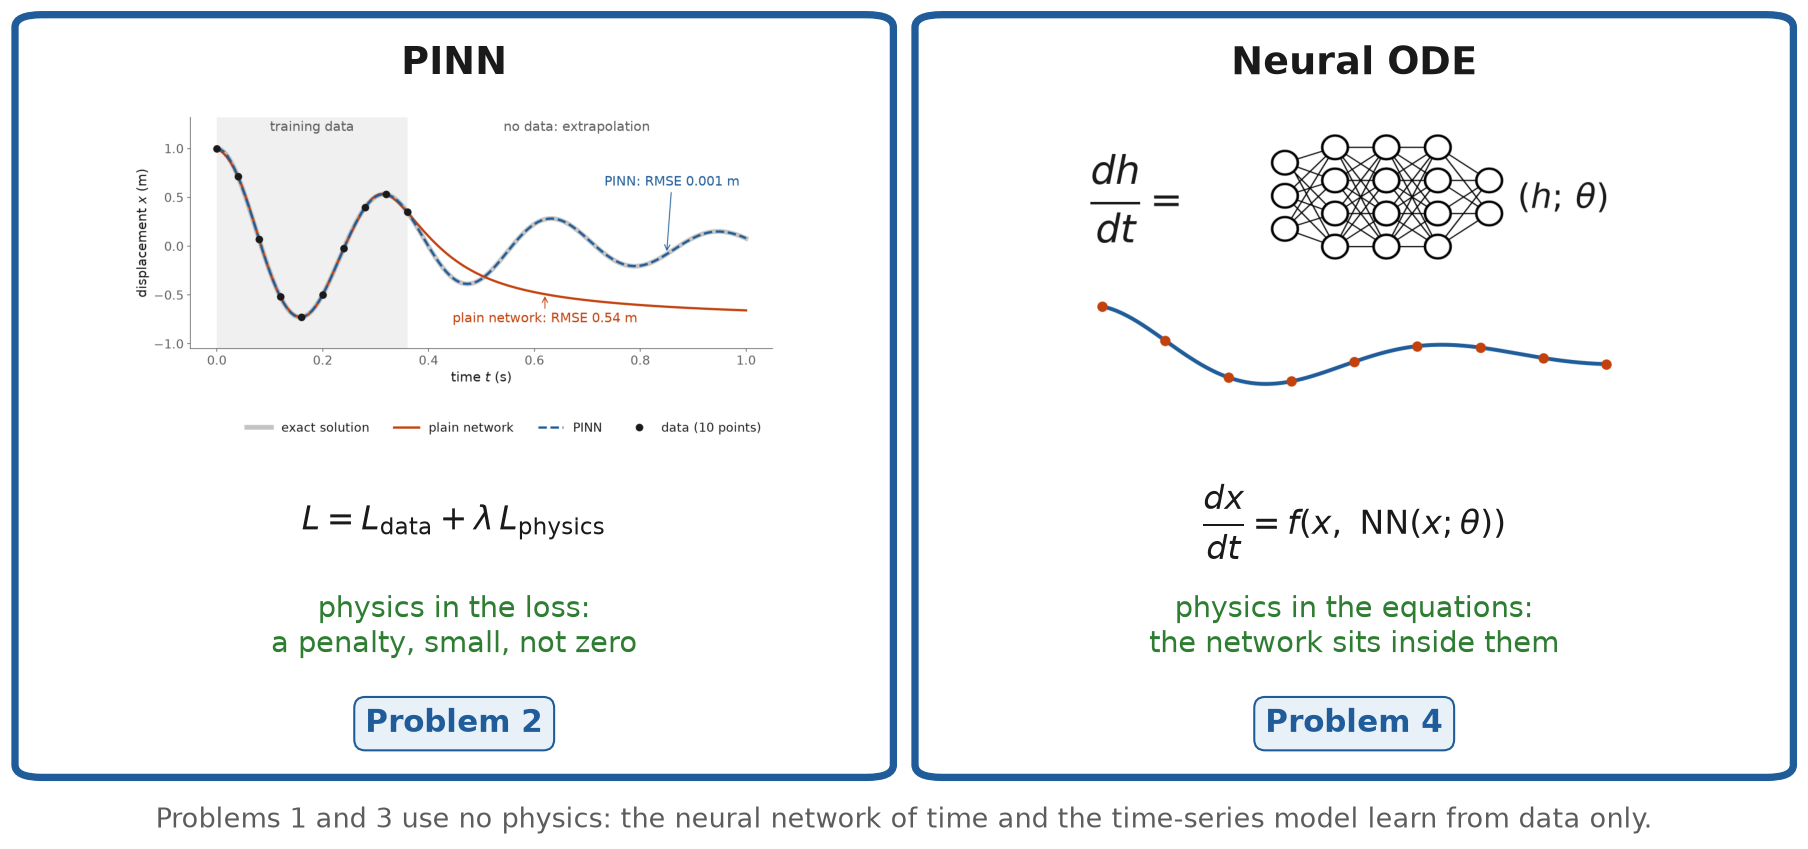

Where the physics goes in this homework, from Lecture 13: the PINN puts it in the loss (Problem 2), and the neural ODE puts it in the equations (Problem 4).

Points: Problem 1, 1; Problem 2, 1.5; Problem 3, 1; Problem 4, 1.5; Problem 5, 1. Your TA grades the PDF. A model that fails, reported and explained, loses no points.

## The bioreactor

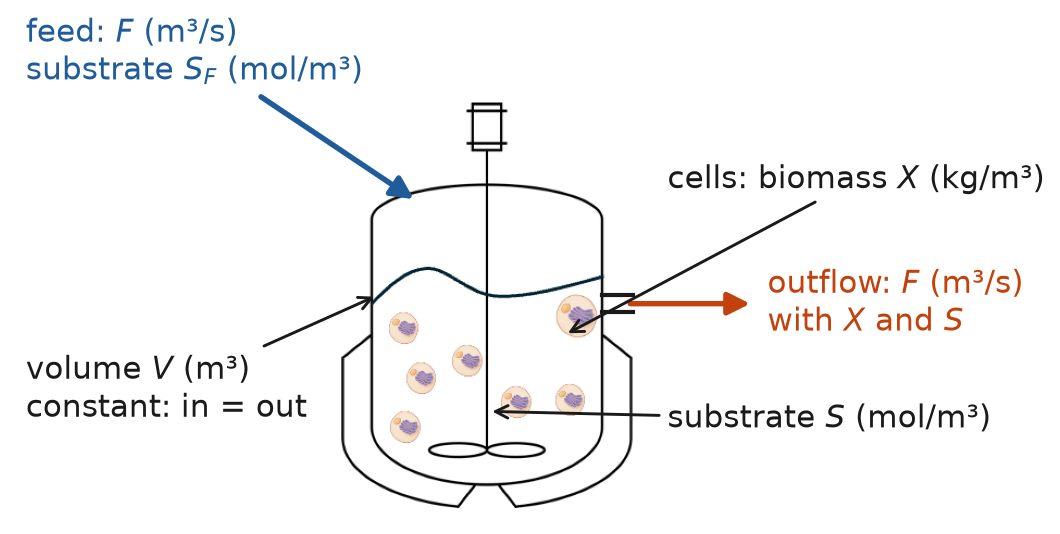

The feed enters at rate $F$ with substrate concentration $S_F$. The outflow leaves at the same rate, at the reactor concentrations $X$ and $S$, so the volume $V$ is constant.

The model consists of two dynamic mass balances, one for the biomass $X$ and one for the substrate $S$:

$$
\frac{dX}{dt} = \underbrace{-\frac{F}{V}\,X}_{\text{outflow}} + \underbrace{\mu(S)\,X}_{\text{growth}}
$$

$$
\frac{dS}{dt} = \underbrace{\frac{F}{V}\,(S_F - S)}_{\text{feed} - \text{outflow}} - \underbrace{\frac{\mu(S)}{Y(S)}\,X}_{\text{consumption}}
$$

where $\mu(S)$ is the specific growth rate and $Y(S)$ the yield:

$$
\mu(S) = 10^{-3}\,S\,e^{-S/120}
$$

$$
Y(S) = 5.4 \cdot 10^{-3} + 1.8 \cdot 10^{-4}\,S
$$

The constants are those of the original model. In $\mu$: $10^{-3}$ m³/(mol·s), and 120 mol/m³, the substrate concentration at which $\mu$ peaks (above it, more substrate slows the growth). In $Y$: $5.4 \cdot 10^{-3}$ kg/mol and $1.8 \cdot 10^{-4}$ kg·m³/mol².

| Symbol | Meaning | Value | Units |
|---|---|---|---|
| $X$ | Biomass concentration | state | kg/m³ |
| $S$ | Substrate concentration | state | mol/m³ |
| $\mu(S)$ | Specific growth rate | equation above | 1/s |
| $Y(S)$ | Yield: biomass made per substrate consumed | equation above | kg/mol |
| $V$ | Reactor volume: a cylinder of radius 3 m and height 5.7 m | $\pi \cdot 3^2 \cdot 5.7$ | m³ |
| $F$ | Feed and outflow rate | 5.02597 | m³/s |
| $S_F$ | Substrate concentration in the feed | 300 | mol/m³ |

## The data

- Columns: `experiment` (1 to 5), `t` (s), `X` (kg/m³), `S` (mol/m³). One sample every 5 s.
- Experiments 1 to 4: 0 to 100 s, 21 samples each.
- Experiment 5: 0 to 300 s, 61 samples. Problems 1 and 2 train on its first 40 s. Its measurements after 40 s are the test.
- The first sample of each experiment ($t = 0$) is the exact initial condition. The others are measurements with Gaussian noise: standard deviation 0.05 kg/m³ on $X$ and 1 mol/m³ on $S$.

| Experiment | $X_0$ (kg/m³) | $S_0$ (mol/m³) | Measured | Use |
|---|---|---|---|---|
| 1 | 5.0 | 10 | 0 to 100 s | Training for Problems 3 and 4 |
| 2 | 2.0 | 20 | 0 to 100 s | Training for Problems 3 and 4 |
| 3 | 4.0 | 120 | 0 to 100 s | Training for Problems 3 and 4 |
| 4 | 2.5 | 60 | 0 to 100 s | Training for Problems 3 and 4 |
| 5 | 3.0 | 80 | 0 to 300 s | First 40 s: training for Problems 1 and 2. After 40 s: **test** |

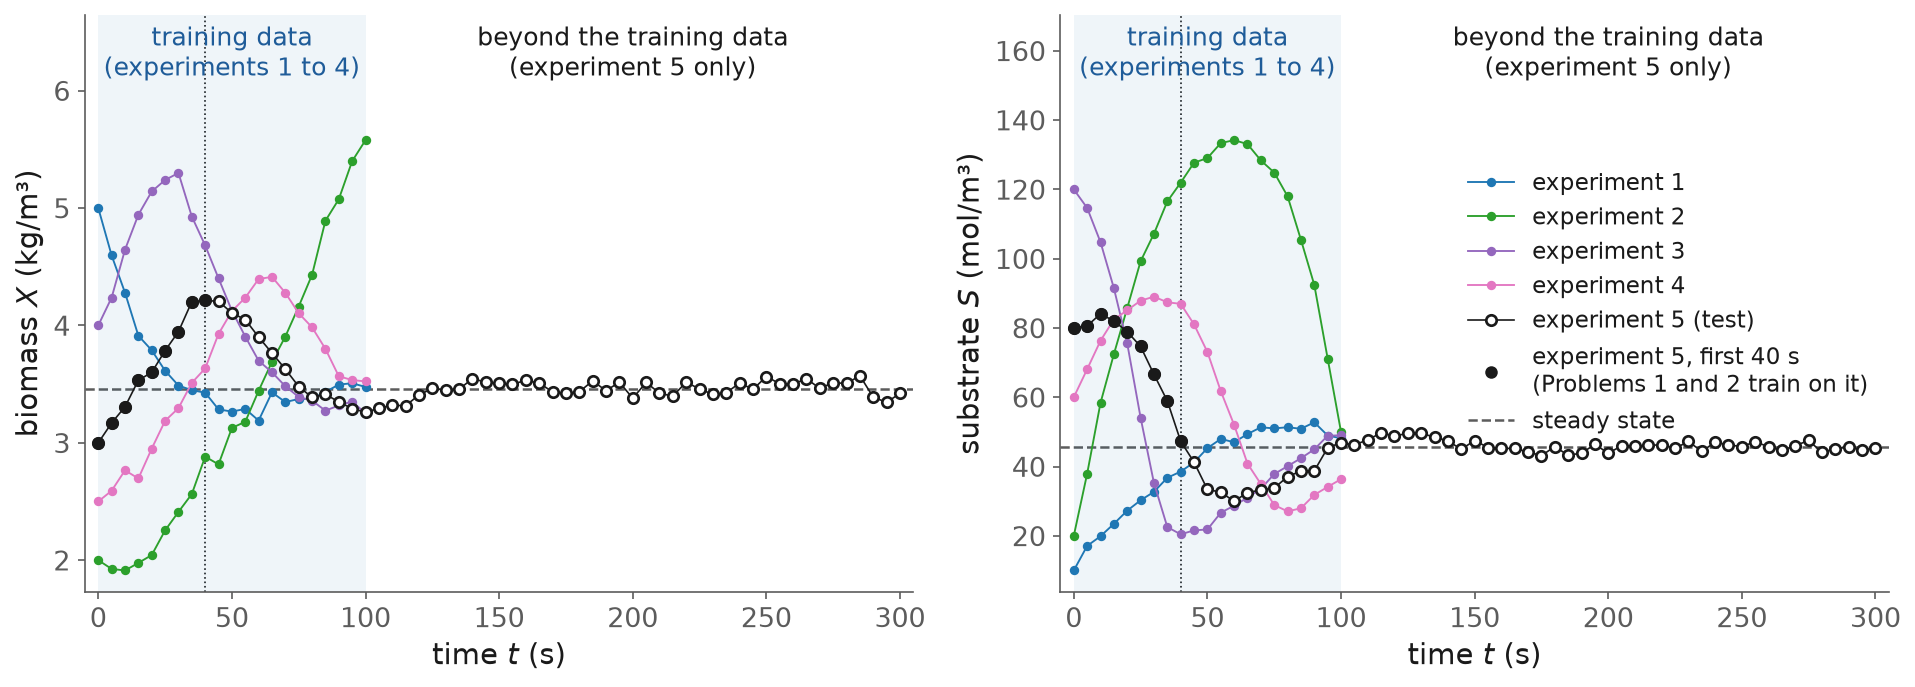

The training data: experiments 1 to 4 (0 to 100 s), and the first 40 s of experiment 5 for Problems 1 and 2. The test: experiment 5 after 40 s.

## Set-up

Run the two cells below first. The first installs the packages Colab may not have: Equinox, Diffrax and Optax. The second loads the libraries, the data and the model's parameters. Training takes from a few seconds to a few minutes per model on a CPU.

In [ ]:
!pip install -q equinox diffrax optax

In [ ]:
# Libraries
import diffrax                      # ODE solvers written in JAX: integrates the neural ODE (Lecture 13)
import equinox as eqx               # neural networks written in JAX (Lecture 13)
import jax                          # automatic differentiation and compiled math (Lecture 11)
import jax.numpy as jnp             # NumPy's functions, in a form JAX can differentiate
import matplotlib.pyplot as plt
import numpy as np
import optax                        # optimizers for JAX, such as Adam (Lectures 11 and 13)
import pandas as pd
from sklearn.neural_network import MLPRegressor      # Problem 3 (Lecture 9)
from sklearn.pipeline import make_pipeline           # Problem 3 (Lecture 8)
from sklearn.preprocessing import StandardScaler     # Problem 3 (Lecture 8)

# Compute in double precision (float64), as in Lecture 11. JAX's default is single precision.
jax.config.update("jax_enable_x64", True)

# The data: one row per sample, with the columns
#   experiment (1 to 5), t (s), X (kg/m3), S (mol/m3)
df = pd.read_csv("https://kitchingroup.cheme.cmu.edu/f26-06763/a05-bioreactor.csv")

# The model's parameters
V = np.pi * 3**2 * 5.7      # m3, reactor volume: a cylinder of radius 3 m and height 5.7 m
F = 5.02597                 # m3/s, feed and outflow rate
SF = 300.0                  # mol/m3, substrate concentration in the feed


def mu(S):
    # Specific growth rate (1/s) at the substrate concentration S (mol/m3).
    # It rises with S, peaks at S = 120 mol/m3, and falls again (substrate inhibition).
    return 1e-3 * S * jnp.exp(-S / 120)


def Y(S):
    # Yield (kg of biomass made per mol of substrate consumed) at the substrate concentration S (mol/m3)
    return 5.4e-3 + 1.8e-4 * S

## Notes for all problems
- **Problems 1 and 2**, the models of one trajectory, train on experiment 5 from 0 to 40 s, its first 9 samples.
- **Problems 3 and 4**, the models of the reactor, train on experiments 1 to 4. From experiment 5 they use only its initial condition, $(X_0, S_0) = (3.0, 80)$.
- Every model predicts experiment 5 at $t = 0, 5, \ldots, 300$ s. Its measurements after 40 s are the test, in Problem 5.
- JAX takes NumPy arrays, not pandas columns. The column `t` holds integers, so read the times as floats with `df["t"].astype(float).to_numpy()`, like every other time array in the notebook (`jax.grad` refuses integer inputs). Read `X` and `S` with `.to_numpy()` too.
- Build time grids with `np.linspace` (Lecture 13), which gives floats.
- Inside a function that JAX differentiates or integrates, write the math with `jnp` (`jnp.exp`), not `np`.
- `l13-neural-dae.ipynb` imports packages A5 does not need (`pyomo`, `sindae`). Copy only the cells you need.
- A model is allowed to fail. Report what you get and explain it.

## 1. Neural network of time
Consider the plain network of Lecture 13: a neural network that maps time to the states, $t \mapsto (X, S)$, trained on data only.

a) Run the cell below. It codes the network:

In [ ]:
# The network: a multilayer perceptron (MLP) that maps the time t to (X, S)
net = eqx.nn.MLP(
    in_size=1,                    # one input: the time t (s)
    out_size=2,                   # two outputs: X (kg/m3) and S (mol/m3)
    width_size=32,                # 32 neurons in each hidden layer
    depth=3,                      # 3 hidden layers
    activation=jnp.tanh,          # the activation function of the hidden layers
    key=jax.random.PRNGKey(0),    # the random seed of the initial weights
)


def model(net, t):
    # X and S predicted by the network at the time t (s), as the array [X, S].
    # The network takes an array as its input, so t goes in as the one-element array [t].
    return net(jnp.array([t]))

b) Train it on the 9 samples of experiment 5 from 0 to 40 s. In the cell below, build `t_fit`, their 9 times, and `y_fit`, their 9 rows of $(X, S)$, as NumPy arrays.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


Then run the cell below. As in Lecture 13, training the network solves

$$
\min_\theta \; \mathcal{L}_\text{data}(\theta)
$$

$$
\mathcal{L}_\text{data}(\theta) = \frac{1}{2N} \sum_{i=1}^{N} \Big[\big(X_\text{NN}(t_i;\theta) - X_i\big)^2 + \big(S_\text{NN}(t_i;\theta) - S_i\big)^2\Big]
$$

where:
- $\theta$: the weights and biases of the network;
- $N = 9$: the number of training samples, at $t_i = 0, 5, \ldots, 40$ s;
- $X_i$ and $S_i$: the measurements at $t_i$; $X_\text{NN}(t_i;\theta)$ and $S_\text{NN}(t_i;\theta)$: the network's outputs there;
- $2N = 18$: the number of squared errors in the sum, 2 states ($X$ and $S$) at each of the 9 samples, so $\mathcal{L}_\text{data}$ is their mean. This is what `jnp.mean` computes in `loss_nn`.

The cell defines this loss, `loss_nn`, and a training function, and trains the network:
- `jax.vmap` (JAX; Lectures 11 and 13) evaluates `model` at all 9 times at once.
- `train` is the training step of `l13-neural-dae.ipynb` (Equinox and Optax; Lecture 13) inside a function, so that Problems 1, 2 and 4 can call it with their own loss. The step of `l13-pinn-jax.ipynb` does not work on an Equinox network.

In [ ]:
def loss_nn(net):
    # L_data: the mean squared error of the network against the 9 samples.
    # jax.vmap evaluates model(net, t) at every time in t_fit at once
    # (in_axes=(None, 0): the same network for all, one time per row).
    pred = jax.vmap(model, in_axes=(None, 0))(net, t_fit)     # shape (9, 2): X and S
    # the mean over the 9 samples and the 2 states: 1/(2N) times the sum of squared errors
    return jnp.mean((pred - y_fit) ** 2)


def train(loss, net, steps, opt):
    # Minimize loss(net) over the network's weights with the optimizer opt, for a fixed
    # number of steps. This is the training loop of l13-neural-dae.ipynb, written as a
    # function so that Problems 1, 2 and 4 can call it with their own loss.

    # The optimizer's memory: Adam keeps running averages of past gradients.
    # eqx.filter(net, eqx.is_array) keeps only the numbers of the network, its weights.
    state = opt.init(eqx.filter(net, eqx.is_array))

    # One optimization step. @eqx.filter_jit compiles it the first time it runs, so the
    # thousands of steps that follow run fast.
    @eqx.filter_jit
    def step(net, state):
        # the value of the loss and its gradient with respect to every weight
        value, grads = eqx.filter_value_and_grad(loss)(net)
        # Adam turns the gradient into a change of each weight
        updates, state = opt.update(grads, state, net)
        # the network with the changed weights
        net = eqx.apply_updates(net, updates)
        return net, state, value

    for i in range(steps):
        net, state, value = step(net, state)

    # the loss of the trained network, after the last update
    print(f"final loss after {steps} steps: {float(loss(net)):.3g}")
    return net


# Adam with a learning rate of 0.001 (Lecture 13), for 20,000 steps
net_nn = train(loss_nn, net, 20_000, optax.adam(1e-3))

c) Evaluate `net_nn` at $t = 0, 5, \ldots, 300$ s with `jax.vmap(model, in_axes=(None, 0))`. Plot $X$ and $S$ with the measurements, marking the 40 s it trained on. How good is it before 40 s, and after? Why?

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


*Your answer (double-click this cell to edit it):*

## 2. PINN
Consider the PINN of Lecture 13: the network of Problem 1, trained on the same data and on the residuals of the model's equations. For this reactor the residuals are

$$
r_X = \frac{dX}{dt} + \frac{F}{V}\,X - \mu(S)\,X
$$

$$
r_S = \frac{dS}{dt} - \frac{F}{V}\,(S_F - S) + \frac{\mu(S)}{Y(S)}\,X
$$

with $X$ and $S$ the network's outputs.

a) Run the cell below. It codes the residuals. $dX/dt$ and $dS/dt$ come from `jax.grad` (JAX; Lectures 11 and 13) of each output with respect to $t$.

In [ ]:
def residuals(net, t):
    # The residuals of the two balances at the time t (s). They are zero when the
    # network's X(t) and S(t) satisfy the model exactly.

    # X and S predicted by the network at t
    X, S = model(net, t)

    # dX/dt and dS/dt of the network, by automatic differentiation (jax.grad, Lecture 11).
    # X_net and S_net are the network's two outputs, each as a function of t alone.
    def X_net(t):
        return model(net, t)[0]

    def S_net(t):
        return model(net, t)[1]

    dXdt = jax.grad(X_net)(t)        # kg/m3/s
    dSdt = jax.grad(S_net)(t)        # mol/m3/s

    # residual of the biomass balance (kg/m3/s)
    rX = dXdt + F / V * X - mu(S) * X
    # residual of the substrate balance (mol/m3/s)
    rS = dSdt - F / V * (SF - S) + mu(S) / Y(S) * X
    return jnp.array([rX, rS])

b) Run the cell below. It trains the PINN with `train`, from the same starting network `net`. As in Lecture 13, the PINN solves

$$
\min_\theta \; \mathcal{L}_\text{data}(\theta) + \lambda\, \mathcal{L}_\text{physics}(\theta)
$$

$$
\mathcal{L}_\text{physics}(\theta) = \frac{1}{M} \sum_{j=1}^{M} \Big[r_X(t_j;\theta)^2 + r_S(t_j;\theta)^2\Big]
$$

where:
- $\mathcal{L}_\text{data}$: the loss of Problem 1, on the same 9 samples;
- $M = 301$: the number of collocation points, $t_j = 0, 1, 2, \ldots, 300$ s, one every second over the whole prediction;
- $r_X$ (kg/m³/s) and $r_S$ (mol/m³/s): the residuals at $t_j$;
- the factor $1/M$: $\mathcal{L}_\text{physics}$ is the mean of $r_X^2 + r_S^2$ over the 301 points;
- $\lambda = 1$: the weight of the physics loss against the data loss (`lam` in the code). Here the two losses come out of the same order, so neither needs rescaling. Lecture 13 used $\lambda = 10^{-4}$, because its residual was in newtons and much larger than its data loss.

The cell defines this loss, `loss_pinn`.

In [ ]:
# The M = 301 collocation points: one every second from 0 to 300 s
t_phys = np.linspace(0, 300, 301)

# lambda: the weight of the physics loss against the data loss
lam = 1.0


def loss_pinn(net):
    # L_data: the loss of Problem 1, on the 9 samples
    L_data = loss_nn(net)
    # the residuals at the 301 collocation points: shape (301, 2), columns r_X and r_S
    r = jax.vmap(residuals, in_axes=(None, 0))(net, t_phys)
    # L_physics: the mean over the 301 points of r_X^2 + r_S^2
    L_physics = jnp.mean(r[:, 0] ** 2 + r[:, 1] ** 2)
    return L_data + lam * L_physics


# The same optimizer and number of steps as Problem 1, from the same starting network net,
# so that only the loss differs between the two problems
net_pinn = train(loss_pinn, net, 20_000, optax.adam(1e-3))

c) Evaluate `net_pinn` at $t = 0, 5, \ldots, 300$ s and plot it with the measurements and the prediction of Problem 1. How good is it after 40 s, compared with Problem 1? Why does the physics help? Why is the prediction still off?

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


*Your answer (double-click this cell to edit it):*

## 3. Neural-network time-series model
Consider a model that predicts the next sample from the current one:

$$
X_{k+1} = f_X(X_k, S_k)
$$

$$
S_{k+1} = f_S(X_k, S_k)
$$

It is the recursive time-series model of [Lecture 8](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l08/notes.html), with a neural network ([Lecture 9](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l09/notes.html)) as the regression.

Using experiments 1 to 4, do the following:

a) Build the training table: features $X_k$ and $S_k$, targets $X_{k+1}$ and $S_{k+1}$. That is 20 rows per experiment, 80 in total.

Hint: one experiment at a time. For an array `arr` of its 21 samples, the features are `arr[:-1]` and the targets are `arr[1:]`.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


b) Fit $f_X$ and $f_S$, each with `make_pipeline(StandardScaler(), MLPRegressor(solver="lbfgs", random_state=0, max_iter=5000))` (scikit-learn; Lectures 8 and 9).

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


c) Predict experiment 5 recursively (Lecture 8, "Direct and recursive forecasting"). Start from $(3.0, 80)$. At each step, predict $X_{k+1}$ and $S_{k+1}$ from the same $(X_k, S_k)$, then use the pair as the next features. Repeat 60 times.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


d) Plot $X$ and $S$ of your prediction with the measurements of experiment 5. How good is the prediction? Why?

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


*Your answer (double-click this cell to edit it):*

## 4. Neural ODE
Consider the same balances with two networks: $\mu_\text{NN}(S)$, the growth rate in the biomass balance, and $f_\text{NN}(X, S)$, the whole right-hand side of the substrate balance:

$$
\frac{dX}{dt} = -\frac{F}{V}\,X + \mu_\text{NN}(S)\,X
$$

$$
\frac{dS}{dt} = f_\text{NN}(X, S)
$$

The biomass balance keeps its physics. Nothing of the substrate balance is given. The code follows [`l13-neural-dae.ipynb`](https://kitchingroup.cheme.cmu.edu/f26-06763/lectures/l13/l13-neural-dae.html).

a) Run the cell below. It codes the two networks and the right-hand side:

In [ ]:
# The network for the growth rate: S -> mu
mu_net = eqx.nn.MLP(
    in_size=1,                    # one input: S
    out_size=1,                   # one output, turned into mu (1/s) by mu_nn below
    width_size=16,                # 16 neurons in each hidden layer
    depth=2,                      # 2 hidden layers
    activation=jnp.tanh,          # the activation function of the hidden layers
    key=jax.random.PRNGKey(0),    # the random seed of the initial weights
)

# The network for the whole right-hand side of the substrate balance: (X, S) -> dS/dt
f_net = eqx.nn.MLP(
    in_size=2,                    # two inputs: X and S
    out_size=1,                   # one output: dS/dt (mol/m3/s)
    width_size=16,                # 16 neurons in each hidden layer
    depth=2,                      # 2 hidden layers
    activation=jnp.tanh,          # the activation function of the hidden layers
    key=jax.random.PRNGKey(1),    # a different seed from mu_net
)

# Both networks together: their weights are the theta that training adjusts
nets = (mu_net, f_net)


def mu_nn(mu_net, S):
    # The learned growth rate (1/s) at the substrate concentration S (mol/m3).
    # - S / 100: S is of order 100 mol/m3, so the network's input is of order 1.
    # - softplus(z) = log(1 + exp(z)) is always positive, as a growth rate must be.
    # - 0.05: a network's output is of order 1, and the true mu is at most 0.044 1/s,
    #   so the factor 0.05 gives mu the right size from the first step of training.
    return 0.05 * jax.nn.softplus(mu_net(jnp.array([S / 100]))[0])


def balances(t, x, nets):
    # The right-hand side of the neural ODE: dX/dt and dS/dt at the state x = [X, S].
    # The equations do not depend on t, but diffrax passes it, so it is an argument.
    mu_net, f_net = nets
    X, S = x
    # biomass balance (kg/m3/s): the outflow term is the known physics, mu is learned
    dXdt = -F / V * X + mu_nn(mu_net, S) * X
    # substrate balance (mol/m3/s), learned whole; X / 5 and S / 100 bring the inputs to order 1
    dSdt = f_net(jnp.array([X / 5, S / 100]))[0]
    return jnp.array([dXdt, dSdt])

b) Run the cell below. It simulates with `diffrax.diffeqsolve` (Diffrax; Lecture 13):

In [ ]:
def simulate(nets, x0, ts):
    # Integrate the neural ODE from the initial condition x0 = [X0, S0], and return X and S
    # at the times ts: an array of shape (number of times, 2). It is adapted from
    # l13-neural-dae.ipynb. Diffrax is written in JAX, so the gradient of anything
    # computed from this solution can be taken with respect to the networks' weights.
    sol = diffrax.diffeqsolve(
        diffrax.ODETerm(balances),          # the right-hand side: dx/dt = balances(t, x, nets)
        diffrax.Tsit5(),                    # the integration method: a 5th-order Runge-Kutta method
        t0=0.0,                             # start time (s)
        t1=ts[-1],                          # end time (s): the last time asked for
        dt0=0.5,                            # first step size (s); the controller then adapts it
        y0=x0,                              # initial condition [X0, S0]
        args=nets,                          # passed to balances as its third argument
        saveat=diffrax.SaveAt(ts=ts),       # return the solution at the times ts
        stepsize_controller=diffrax.PIDController(
            rtol=1e-6,                      # relative error tolerance of each step
            atol=1e-8,                      # absolute error tolerance of each step
        ),
    )
    return sol.ys

c) Train on experiments 1 to 4. As in Lecture 13, the neural ODE solves

$$
\min_\theta \; \frac{1}{2 \cdot 4 \cdot 21} \sum_{e=1}^{4} \sum_{k=1}^{21} \left[\left(\frac{X_e(t_k;\theta) - X_{e,k}}{\sigma_X}\right)^2 + \left(\frac{S_e(t_k;\theta) - S_{e,k}}{\sigma_S}\right)^2\right]
$$

where $X_e(t;\theta)$ and $S_e(t;\theta)$ solve the balances from the initial condition of experiment $e$:

$$
\frac{dX_e}{dt} = -\frac{F}{V}\,X_e + \mu_\text{NN}(S_e;\theta)\,X_e
$$

$$
\frac{dS_e}{dt} = f_\text{NN}(X_e, S_e;\theta)
$$

$$
X_e(0) = X_{0,e}
$$

$$
S_e(0) = S_{0,e}
$$

where:
- $\theta$: the weights of both networks;
- $e = 1, \ldots, 4$: the four training experiments;
- $k = 1, \ldots, 21$: their 21 sample times, $t_k = 0, 5, \ldots, 100$ s;
- $X_{e,k}$ and $S_{e,k}$: the measurements of experiment $e$ at $t_k$;
- $X_{0,e}$ and $S_{0,e}$: the initial condition of experiment $e$, its sample at $t = 0$;
- $\sigma_X$ (kg/m³) and $\sigma_S$ (mol/m³): the standard deviations of $X$ and of $S$ over all samples of experiments 1 to 4. Dividing by them makes both errors dimensionless and of similar size, so that $S$, an order of magnitude larger than $X$, does not dominate the sum;
- $2 \cdot 4 \cdot 21 = 168$: the number of terms in the sum, 2 states at 21 times in 4 experiments, so the objective is the mean of the 168 squared, scaled errors. This is what `jnp.mean` computes in `loss_node`.

`simulate` solves the balances, so every evaluation of the objective simulates the four experiments. In the cell below, define:
- `x0s`, their four initial conditions, `ts`, their 21 sample times, and `ys`, their measurements, of shape (4, 21, 2);
- `sigma`, the standard deviations $\sigma_X$ and $\sigma_S$, with `np.std` as in Lecture 13;
- `loss_node(nets)`: simulate the four experiments at once with `jax.vmap(simulate, in_axes=(None, 0, None))(nets, x0s, ts)`, and return the objective above.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


Then run the cell below. It trains for 10,000 steps with `train` (Problem 1) and a cosine schedule (Optax; Lecture 13). `train` accepts the pair `nets`, because `eqx.filter` and `eqx.filter_value_and_grad` work on a tuple of networks.

In [ ]:
# Adam with a learning rate that starts at 0.01 and decays along a cosine to 5% of that
# (alpha=0.05) over the 10,000 steps, as in l13-neural-dae.ipynb
opt = optax.adam(optax.cosine_decay_schedule(1e-2, 10_000, alpha=0.05))

# Train the pair of networks. train works on the pair because eqx.filter and
# eqx.filter_value_and_grad accept a tuple of networks.
# nets is replaced by the trained networks: to train again from the start, for example
# after changing loss_node, run the cell of 4(a) again first.
nets = train(loss_node, nets, 10_000, opt)

d) Predict experiment 5 by integrating from its initial condition with `simulate`, passing the initial condition as an array, `jnp.array([3.0, 80.0])` (a Python list fails inside Diffrax). It is a new initial-value problem: do not retrain, and use only its initial condition. Plot it with the measurements.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


e) Evaluate `mu_nn` with the trained growth-rate network, `nets[0]`, at $S = 0, 10, \ldots, 300$ mol/m³: `jax.vmap(mu_nn, in_axes=(None, 0))(nets[0], S)` (JAX; Lectures 11 and 13). Plot it with the true $\mu(S)$ on the same grid. Where do they agree? Where not, and why?

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


*Your answer (double-click this cell to edit it):*

## 5. Compare
a) Plot $X$ and $S$ of experiment 5 in one figure: the measurements and your four predictions, with the 40 s of Problems 1 and 2 marked.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


b) Compute the root mean square error (RMSE) of each prediction, for $X$ and for $S$, against the $N = 52$ measurements of experiment 5 after 40 s ($t = 45$ to 300 s). No model trained on them. Report the RMSEs in a table:

$$
\text{RMSE} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} \left(\hat{y}_i - y_i\right)^2}
$$

where $N = 52$ is the number of measurements of experiment 5 after 40 s ($t = 45, 50, \ldots, 300$ s), $y_i$ a measurement and $\hat{y}_i$ the prediction at the same time.

Note: the measurement noise sets a floor. No model can score much below 0.05 kg/m³ on $X$ or 1 mol/m³ on $S$, the standard deviations of the noise.

In [ ]:
# ADD YOUR CODE HERE  -- feel free to add additional code or markdown blocks if needed 


c) Which model would you use to predict a sixth experiment from its initial condition only? Why can the models of the reactor (Problems 3 and 4) do it, while the models of one trajectory (Problems 1 and 2) cannot?

*Your answer (double-click this cell to edit it):*

## Generative AI statement (please indicate if you used generative AI, where and how):

*Write your statement here (double-click this cell to edit it): which tool you used, for which problems, and how. If you did not use generative AI, write "None".*

## End of homework.